# LinearRegression: 머신러닝 회귀 

# A) 단순선형회귀 모델 구현 

## 1. 문제 정의 

- 농어 데이터에서 농어의 길이로 농어의 몸무게를 예측하는 회귀 모델을 구현해보자 

In [1]:
# !pip install scikit-learn

In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split # 데이터를 훈련용, 테스트용으로 분리시키기 위한 함수
from sklearn.linear_model import LinearRegression # 선형회귀 모델 클래스 
from sklearn.metrics import mean_squared_error, root_mean_squared_error # 회귀모델 성능평가지표 함수 

## 2. 데이터 로드 및 탐색 

- 데이터: 농어 데이터
- 포맷: csv
- features(특성):
    - length: 농어 길이 
- target:
    - weight: 농어 몸무게 

In [3]:
df = pd.read_csv("../data/perch.csv")

print(df.shape)
df.head()

(56, 2)


,length,weight
0,8.4,5.9
1,13.7,32.0
2,15.0,40.0
3,16.2,51.5
4,17.4,70.0


Text(0, 0.5, 'weight')

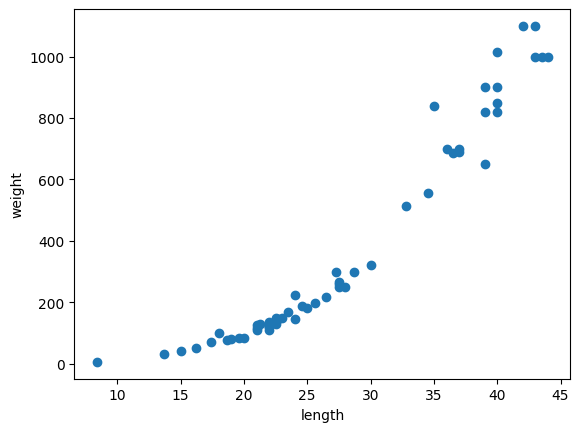

In [4]:
# 농어의 길이에 따라 몸무게가 어떻게 변하는지 데이터의 분포 및 관계성(선형적인 관계가 있는지) 확인해보기 

plt.scatter(df["length"], df["weight"])

plt.xlabel("length")
plt.ylabel("weight")

## 3. 데이터 분리 

### 3.1 Features, Target 분리 

In [5]:
x = df[["length"]]
y = df[["weight"]]

print(df.shape)
print(x.shape)
print(y.shape)

(56, 2)
(56, 1)
(56, 1)


In [6]:
display(x.head())
display(y.head())

,length
0,8.4
1,13.7
2,15.0
3,16.2
4,17.4


,weight
0,5.9
1,32.0
2,40.0
3,51.5
4,70.0


## 3.2 Train, Test 데이터 분리 

In [7]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(44, 1) (44, 1) (12, 1) (12, 1)


## 4. 모델링 

## 4.1 모델 학습 

In [8]:
# 모델 객체 정의 
model = LinearRegression()

# 선형 회귀 모델 학습 
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## 4.2 가중치와 편향 확인 

In [9]:
# 학습된 가중치(weight) 값 출력 
coef = model.coef_

print(type(coef))
print(coef)
np.round(coef, 4) # 소수점아래 4자리까지만 표현 

# 출력 결과가 2차원인 이유:
# - coef_는 항상 (타겟 개수, 피처 개수) 형태(shape)로 저장됨
# - 현재 학습된 데이터는 피처1개, 타겟1개 이므로 (1, 1)형태의 배열이 출력됨 
# - 만약, 피처가 2개라면 -> [[weight1, weight2]] 형태로 각 피처에 해당하는 가중치 2개가 2차원 배열 형태(1, 2)로 출력됨

<class 'numpy.ndarray'>
[[39.05365447]]


array([[39.0537]])

In [10]:
# 학습된 절편(bias)값 출력 
intercept = model.intercept_

print(type(intercept))
print(intercept)
np.round(intercept, 4)

<class 'numpy.ndarray'>
[-714.36518394]


array([-714.3652])

## 5. 모델 성능 평가 

- 회귀모델 성능평가지표를 통해 모델 성능 평가해보기 
- 사용할 성능평가지표: 결정계수($R^2$), MSE, RMSE

### 5.1 결정계수($R^2$) 확인 

- .score(): 회귀모델에서 score는 결정계수($R^2$)를 의미하며, 1에 가까울수록 성능이 좋아짐을 의미 

In [11]:
# train 데이터로 모델 성능 평가 
print("train 데이터의 결정계수:", round(model.score(x_train, y_train), 4))

# test 데이터로 모델 성능 평가 
print("test 데이터의 결정계수:", round(model.score(x_test, y_test), 4))

# 두 수치의 차이 확인을 통해 모델이 train 데이터에 과대적합 됐다고 볼 수 있음 
# 과대적합: 모델이 학습데이터를 너무 잘 외워서 새로운 데이터(test)에 대해서는 성능이 떨어지는 상태(즉, 일반화 능력을 상실한 상태)

train 데이터의 결정계수: 0.9363
test 데이터의 결정계수: 0.836


## 5.2 MSE(Mean Squared Error) 확인 

In [12]:
# 과대적합 확인을 위해 train 데이터를 통한 예측치와 test데이터를 통한 예측치 모두 추출 

pred_train = model.predict(x_train)
pred_test = model.predict(x_test)

In [13]:
# MSE 
# 오차 제곱 평균: 정답지와 예측치의 오차의 제곱이라 실제 데이터의 단위를 쓸 수 없다는 단점이 있음 

train_mse = mean_squared_error(y_train, pred_train)
test_mse = mean_squared_error(y_test, pred_test)

print("train MSE:", round(train_mse, 4))
print("test MSE:", round(test_mse, 4))

train MSE: 7543.3498
test MSE: 19107.4113


## 5.3 RMSE(Root Mean Squared Error) 확인 

In [14]:
# RMSE:
# 오차 제곱 평균에 제곱근을 취한 형태로, 정답지와 예측치 오차의 제곱에 다시 제곱근을 취한 형태이기 때문에 
# 실제 데이터의 단위를 적용하고 성능을 이해하기에 적합

train_rmse = root_mean_squared_error(y_train, pred_train)
test_rmse = root_mean_squared_error(y_test, pred_test)

print("train RMSE:", round(train_rmse, 4))
print("test RMSE:", round(test_rmse, 4))

train RMSE: 86.8525
test RMSE: 138.2296


# B) 다항 회귀 모델 구현 

## 1. A의 문제 파악해보기 

### 1.1 시각화를 위한 예제 데이터 및 이에 대한 예측값 생성 

In [15]:
# 모델에 입력되는 데이터 형태 확인 

print(type(x_train))
print(x_train.shape)
x_train.head()

# 모델에는 2차원 형태의 arraylike 데이터가 입력됨을 알 수 있음 

<class 'pandas.core.frame.DataFrame'>
(44, 1)


,length
34,28.0
30,27.3
8,19.6
17,22.0
6,18.7


In [16]:
# 학습한 모델을 통해 50cm농어의 길이로 몸무게 예측해보기 
# 모델이 받아들이는 데이터 형식(2차원 arraylike)에 맞춰 데이터 전달 
pred_50 = model.predict([[50]])

# pred_50은 반환값이 numpy array이므로 numpy에서 제공하는 round 메소드를 통해 소수점 아래 4자리까지 표현해보기
print(np.round(pred_50, 4))

[[1238.3175]]


/opt/anaconda3/envs/sesac-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## 1.2 문제점 파악을 위한 시각화 

- 농어의 길이가 50일 때 예측되는 농어의 몸무게를 그래프상에 찍어 실제 데이터와 위치를 비교해보자 

Text(0, 0.5, 'weight')

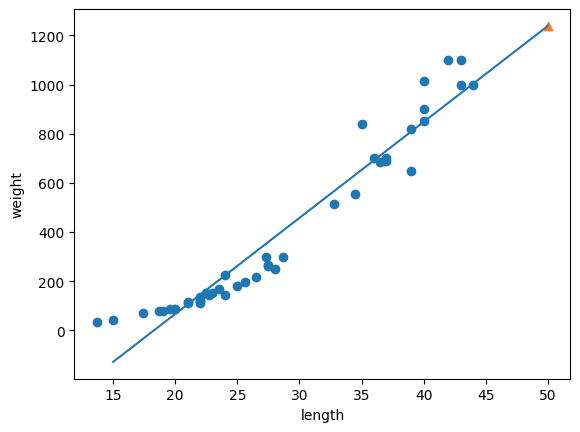

In [17]:
# 훈련데이터의 산점도와 예측 직선을 비교해보기 

# 훈련데이터 산점도 그리기
plt.scatter(x_train, y_train)
# 농어의 길이 15, 50cm와 학습된 파라미터를 통해 모델이 표현하는 직선 그려보기 
plt.plot([15, 50], [15*model.coef_[0]+model.intercept_, 50*model.coef_[0]+model.intercept_])
# 50cm 농어에 대한 몸무게 위치 찍어보기 
plt.scatter(50, 1238.3, marker="^")

plt.xlabel("length")
plt.ylabel("weight")

# 현재 모델이 그리는 직선은 왼쪽 아래로 뻗어있어서 농어의 길이가 15cm 이하일 경우 0g으로 예측하게 됨 
# 실제 데이터에 대한 산점도는 직선과 달리 농어의 길이가 짧아질수록 0이 되지 않고 0에 수렴하는 곡선 형태를 보임
# 따라서 우리는 최적의 직선이 아닌 최적의 곡선(2차방정식)을 찾아야 함 (즉, 모델이 좀 더 복잡해질 필요가 있음)

In [18]:
pred_test

array([[-386.31448636],
       [ -11.3994034 ],
       [ 359.61031411],
       [ 117.47765637],
       [ 164.34204174],
       [ 847.78099505],
       [ 457.2444503 ],
       [ 246.35471614],
       [ 808.72734057],
       [ 105.76156003],
       [ 984.46878571],
       [ -81.69598145]])

## 2. 특성 추가 

- 2차 방정식의 그래프(곡선 형태의 그래프)를 그리기 위해 기존의 특성(농어의 길이)을 제곱하여 새로운 특성 생성하기 
- 2차 방정식 수식: $y = ax^2 + bx + c$

In [19]:
# 데이터 다시 불러오기 

df = pd.read_csv("../data/perch.csv")

print(df.shape)
df.head()

(56, 2)


,length,weight
0,8.4,5.9
1,13.7,32.0
2,15.0,40.0
3,16.2,51.5
4,17.4,70.0


In [20]:
# featrue, target 분리 
X = df[["length"]]
y = df[["weight"]]

# x에 새로운 Feature 생성하기 
X["squared_length"] = df["length"]**2

# 결과 확인 
print(X.shape, y.shape)
X.head()

(56, 2) (56, 1)


,length,squared_length
0,8.4,70.56
1,13.7,187.69
2,15.0,225.00
3,16.2,262.44
4,17.4,302.76


## 3. Train, Test 데이터 분리  

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(44, 2) (44, 1) (12, 2) (12, 1)


## 4. 모델 학습 

In [22]:
# 모델 객체 정의 
model = LinearRegression()

# 모델 학습 
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [23]:
weight = model.coef_ 
weight

array([[-22.63525541,   1.03238928]])

In [24]:
bias = model.intercept_ 
bias

array([129.83360653])

## 5. 성능평가 

### 5.1 시각화를 통한 모델 평가 

In [25]:
# 입력 데이터 형태 확인 
X_train.head() # 피처가 2개인 2차원 데이터가 모델에 입력데이터로 전달됨을 알 수 있음 

,length,squared_length
34,28.0,784.00
30,27.3,745.29
8,19.6,384.16
17,22.0,484.00
6,18.7,349.69


In [28]:
# 50cm 농어 데이터에 대한 몸무게 예측 
model.predict([[50, 50**2]]) # 입력 데이터 형태에 맞춰 모델에 전달하여 예측값 추출해보기 

/opt/anaconda3/envs/sesac-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([[1579.0440311]])

ValueError: operands could not be broadcast together with shapes (35,) (2,) 

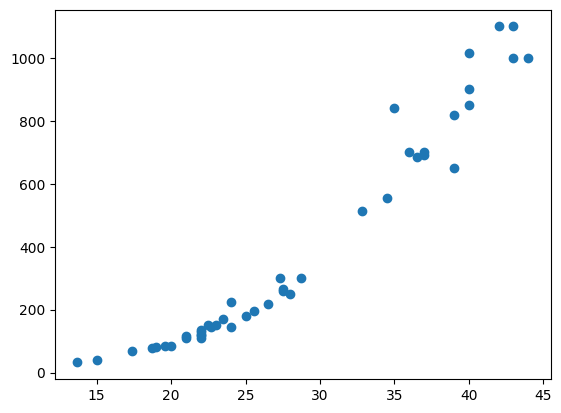

In [ ]:
# 시각화 

# 구간별 곡선을 그리기 위해 15에서 49까지 정수 배열(x좌표) 생성
point = np.arange(15, 50)

# train 데이터 산점도 
plt.scatter(x_train, y_train)
# 농어의 길이 15, 50과 학습된 파라미터를 통해 모델이 표현하는 곡선 그려보기 
plt.plot(point, point*weight[0][0] + point**2*weight[0][1] + bias)
# 50cm 농어에 대한 몸무게 위치 산점도로 찍어보기 
plt.scatter(50, 1579.0, marker="^")

plt.xlabel("length")
plt.ylabel("weight")

### 4.2 성능평가지표를 통한 모델 성능평가 

In [ ]:
# 결정계수를 통해 모델의 성능을 평가해보자 
print("train 결정계수:", model.score(X_train, y_train))
print("test 결정계수:", model.score(X_test, y_test))

# 성능이 0.01 차이로 과대적합에서 벗어남을 알 수 있음 
# 데이터의 수가 적을 시 test의 성능이 더 좋게 나오는 경우가 있지만 이는 데이터의 크기와 상태에 따라 다르게 해석되기 때문에 
# 현재 결과만 봐서는 과소적합됐다고 보기는 어려움 
# 과소적합: 모델이 너무 단순하거나 학습량이 적어 모델이 충분히 데이터의 패턴을 파악하지 못한 상태로 train과 test 모두 성능이 낮게 나타나는 현상
# 따라서 현재는 모델이 데이터의 패턴을 잘 학습하여 새로운 데이터에 대해서도 일반화 성능이 우수함을 알 수 있음 

train 결정계수: 0.970185494758599
test 결정계수: 0.9801885585527479


## 6. PolynominalFeatures를 활용한 특성 확장 

- PolynominalFeatures: 특성을 생성해주는 변환기 
- 직접 제곱을 계산하지 않고 PolynominalFeatures를 통해 간편하게 특성을 확장해보자 

In [31]:
# 1. 데이터 로드 및 탐색 
df = pd.read_csv("../data/perch.csv")

# 2-1. 데이터 분리: X, y로 분리
X = df[["length"]]
y = df[["weight"]]

# 2-2. 데이터 분리: train, test로 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, y_train.shape, X_test.shape, y_train.shape)

(44, 1) (44, 1) (12, 1) (44, 1)


In [ ]:
# 3. 특성확장 
from sklearn.preprocessing import PolynomialFeatures 

# 변환기 객체 정의 
poly = PolynomialFeatures(include_bias=False) # 편향에 대한 특성 추가는 제외 

# train 데이터에 대하여 변환기 학습 
# train데이터로 데이터의 패턴 및 규칙을 학습: 현재 데이터에서는 어떤 특성을 어떤 순서로 만들지 train데이터를 통해 학습진행
# test데이터로 fit을 하게 되면 test의 정보가 모델 학습과정에 간접적으로 반영되게 됨 
poly.fit(X_train)

# train, test 데이터에 학습된 변환기 적용 
X_train_poly = poly.transform(X_train)
X_test_poly = poly.transform(X_test) # train데이터를 통해 학습된 규칙을 test에도 적용 

print(X_train_poly.shape, X_test_poly.shape)
display(X_train_poly[:5])
display(X_test_poly[:5])

(44, 2) (12, 2)


array([[ 28.  , 784.  ],
       [ 27.3 , 745.29],
       [ 19.6 , 384.16],
       [ 22.  , 484.  ],
       [ 18.7 , 349.69]])

array([[  8.4 ,  70.56],
       [ 18.  , 324.  ],
       [ 27.5 , 756.25],
       [ 21.3 , 453.69],
       [ 22.5 , 506.25]])

In [ ]:
# 새로운 특성이 어떻게 생성됐는지 확인 
poly.get_feature_names_out() # x와 x제곱의 피처로 구성돼있음을 알 수 있음 

array(['length', 'length^2'], dtype=object)

In [36]:
# 4. 모델 학습 
model = LinearRegression()
model.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [37]:
# 5. 성능평가 
print("train 데이터의 결정계수:", round(model.score(X_train_poly, y_train), 4))
print("test 데이터의 결정계수:", round(model.score(X_test_poly, y_test), 4))

train 데이터의 결정계수: 0.9702
test 데이터의 결정계수: 0.9802


# C) 실습1 

## 1. 문제 정의 

- 보스턴 1970년대 거주지에 대한 데이터를 바탕으로 주택 가격 예측해보기 

[진행 과정]
1. 데이터 로드 및 탐색
2. 데이터 분리
    - feature, target 분리
    - train, test 분리 
3. 전처리: 특성 확장
4. 모델 학습  
5. 성능평가  

In [38]:
# 데이터 분석 및 머신러닝 모델 구축에 필요한 라이브러리 import 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_squared_error, root_mean_squared_error 

## 2. 데이터 로드 및 탐색

- 데이터: 1970년대 보스턴 거주지 데이터
- 포맷: csv
- feature(특성):
    - CRIM: 범죄 발생률
    - ZN: 25,000평방 피트를 초과하는 거주 지역의 비율
    - INDUS: 비 상업 지역 넓이 비율
    - CHAS: 찰스강 경계 유무(강의 경계에 위치한 경우는 1, 아니면 0)
    - NOX: 일산화질소 농도
    - RM: 주택 당 거주할 수 있는 방 개수
    - AGE: 1940년 이전에 건축된 소유 주택의 비율
    - DIS: 5개 주요 고용센터까지의 가중 거리
    - RAD: 고속도로 접근 용이도
    - TAX: 10,000달러 당 재산세율
    - PTRATIO: 지역의 교사와 학생 수 비율
    - B: 지역의 흑인 거주 비율
    - LSTAT: 소득 하위 계층의 비율
- Target:
    - MEDV: 보스턴 1978년 주택 가격 중앙값(단위당 1000달러)

# D) 실습2  

In [63]:
df = pd.read_csv("../data/boston_house.csv")

print(df.shape)
df.head()

(506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [64]:
df.info()

# 데이터의 결측치, 데이터 유형 확인 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


## 3. 데이터 전처리 

- 결측치 없음
- 별도로 처리할 object 자료형 존재하지 않음 
- 추후 특성 확장 진행 예정 

# 4. EDA(탐색적 데이터 분석)

In [65]:
# 특성간 상관계수 출력 
# 상관계수: 하나의 값이 변동될 때 나머지 하나의 값이 어떻게 변동되는지에 대한 계수 (-1: 반비례관계, 1: 비례관계, 0: 관계없음)

df.corr() # corr: 기본적으로 피어슨 상관계수로 진행 

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
CRIM,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,-0.385064,0.455621,-0.388305
ZN,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,0.175520,-0.412995,0.360445
INDUS,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,-0.356977,0.603800,-0.483725
CHAS,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,0.048788,-0.053929,0.175260
NOX,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,-0.380051,0.590879,-0.427321
RM,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,0.128069,-0.613808,0.695360
AGE,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,-0.273534,0.602339,-0.376955
DIS,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,0.291512,-0.496996,0.249929
RAD,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,-0.444413,0.488676,-0.381626
TAX,0.582764,-0.314563,0.720760,-0.035587,0.668023,-0.292048,0.506456,-0.534432,0.910228,1.000000,0.460853,-0.441808,0.543993,-0.468536


In [66]:
# !pip install seaborn

<Axes: >

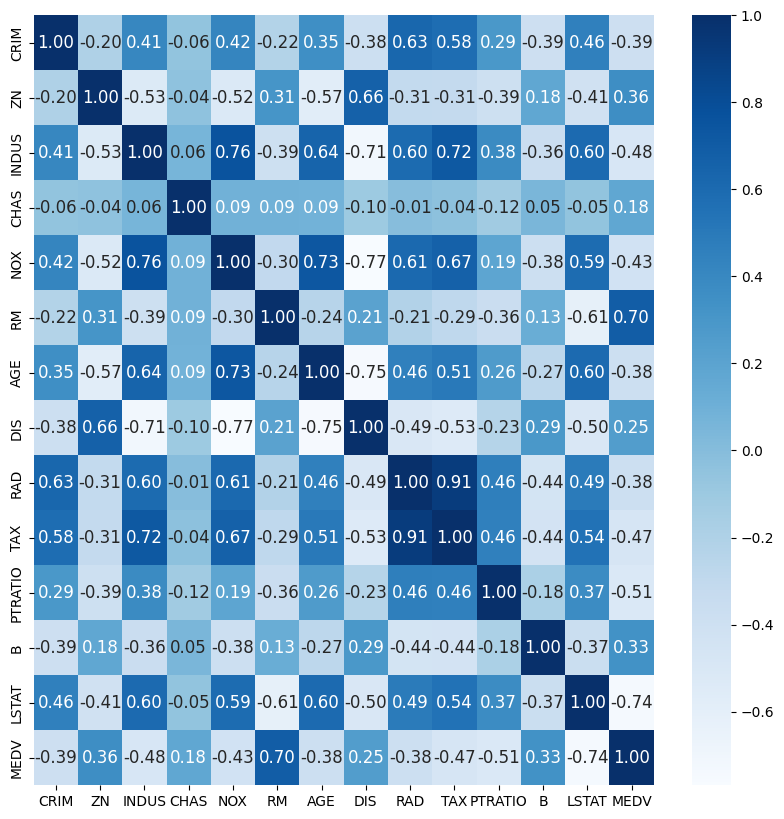

In [67]:
import seaborn as sns 

# 상관계수 히트맵 
plt.figure(figsize=(10, 10))

sns.heatmap(
    df.corr(),
    annot=True,              # 각 셀 값 표시 
    fmt=".2f",               # 소숫점 표시 자릿수 
    annot_kws={"size":12},   # 수치 사이즈
    cmap="Blues"             # 히트맵 색상
)

# 주택 가격(MEDV)과 상관관계가 높은 특성은 RM(주택당 방 개수), LSTAT(소득 하위계층 비율)임을 알 수 있음

## 5. 모델링 

- 모델 선택, 학습, 평가  
- 문제, 정답 및 학습, 평가 데이터로 분리해보기 (학습, 평가 데이터비율은 7:3)

### 5.1 독립변수, 종속변수 분리 

In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [69]:
X = df.iloc[:, :-1]
y = df[["MEDV"]]

print(X.shape, y.shape)

(506, 13) (506, 1)


### 5.2 train, test 분리 

In [70]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(354, 13) (354, 1) (152, 13) (152, 1)


### 5.3 모델 학습 

In [71]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


- $y = w1x1 + w2x2 + w3x3 + ... + w13x13 + b$

In [72]:
# 학습된 선형회귀 모델에 들어간 데이터의 특성 명칭 출력 
model.feature_names_in_

array(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD',
       'TAX', 'PTRATIO', 'B', 'LSTAT'], dtype=object)

In [73]:
# 각 특성별 weight(가중치)값 출력 
model.coef_

array([[-1.33470103e-01,  3.58089136e-02,  4.95226452e-02,
         3.11983512e+00, -1.54170609e+01,  4.05719923e+00,
        -1.08208352e-02, -1.38599824e+00,  2.42727340e-01,
        -8.70223437e-03, -9.10685208e-01,  1.17941159e-02,
        -5.47113313e-01]])

In [74]:
# 피처와 가중치 값 매핑해서 같이 보기 
feature_coef = dict(zip(model.feature_names_in_, np.round(model.coef_[0], 4)))
feature_coef

{'CRIM': np.float64(-0.1335),
 'ZN': np.float64(0.0358),
 'INDUS': np.float64(0.0495),
 'CHAS': np.float64(3.1198),
 'NOX': np.float64(-15.4171),
 'RM': np.float64(4.0572),
 'AGE': np.float64(-0.0108),
 'DIS': np.float64(-1.386),
 'RAD': np.float64(0.2427),
 'TAX': np.float64(-0.0087),
 'PTRATIO': np.float64(-0.9107),
 'B': np.float64(0.0118),
 'LSTAT': np.float64(-0.5471)}

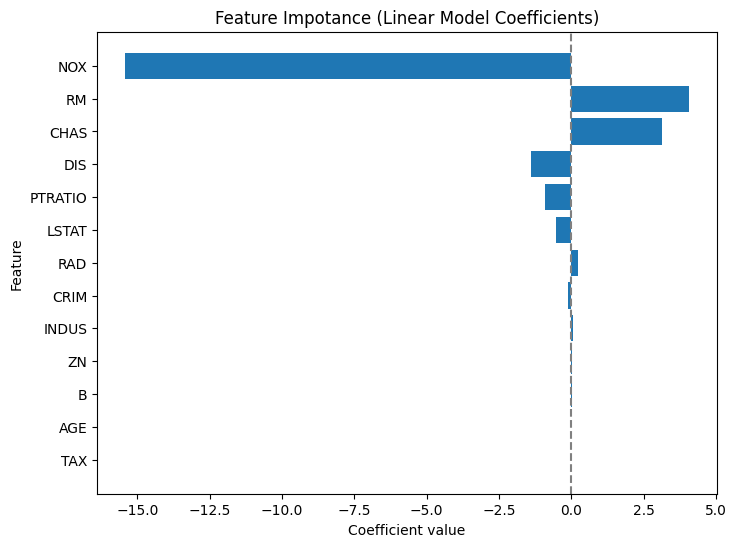

In [75]:
coef_df = pd.DataFrame(
    feature_coef.items(),
    columns=["features", "coef"]
)

# 절댓값 기준 정렬 
coef_df["abs_coef"] = coef_df["coef"].abs()
coef_df = coef_df.sort_values("abs_coef", ascending=True)

# 시각화 
plt.figure(figsize=(8, 6))
plt.barh(coef_df["features"], coef_df["coef"])
plt.axvline(0, color="gray", linestyle="--")
plt.title("Feature Impotance (Linear Model Coefficients)")
plt.xlabel("Coefficient value")
plt.ylabel("Feature")
plt.show()

## 6. 상관계수와 weight의 관계

- feature와 상관계수가 높을 수록 해당 feature의 weight값의 절대값이 높아지는 경향이 있으나, weight값은 다른 특성들과의 조합에 따라 달라질 수 있으므로 상관계수가 높다고 해서 해당 특성의 weight가 반드시 높다고 볼 수는 없음 
- 즉, 상관계수는 두 변수(특성, feature)간의 상관성 정도이고, **weight는 입력되는 모든 특성들을 다 고려하여 종속변수를 예측하게하는 중요도**라고 볼 수 있음
- 따라서, weight값과 상관계수를 같이 고려해주는 게 더 좋음

In [76]:
coef_df

,features,coef,abs_coef
9,TAX,-0.0087,0.0087
6,AGE,-0.0108,0.0108
11,B,0.0118,0.0118
1,ZN,0.0358,0.0358
2,INDUS,0.0495,0.0495
0,CRIM,-0.1335,0.1335
8,RAD,0.2427,0.2427
12,LSTAT,-0.5471,0.5471
10,PTRATIO,-0.9107,0.9107
7,DIS,-1.3860,1.3860


## 7. 모델 평가 

### 7.1 MSE & RMSE

In [80]:
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

# MSE
train_mse = mean_squared_error(pred_train, y_train)
test_mse = mean_squared_error(pred_test, y_test)

# RMSE
train_rmse = root_mean_squared_error(pred_train, y_train)
test_rmse = root_mean_squared_error(pred_test, y_test)

print("train MSE:", round(train_mse, 4))
print("test MSE:", round(test_mse, 4))
print("train RMSE:", round(train_rmse, 4))
print("test RMSE:", round(test_rmse, 4))

print("train, test의 MSE 차이:", round(abs(train_mse - test_mse), 4))
print("train, test의 RMSE 차이:", round(abs(train_rmse - test_rmse), 4))

train MSE: 22.5455
test MSE: 21.5174
train RMSE: 4.7482
test RMSE: 4.6387
train, test의 MSE 차이: 1.028
train, test의 RMSE 차이: 0.1095


In [ ]:
# 실제 정답의 평균 수치 확인 
print("train:\n", y_train.mean())
print("test:\n", y_test.mean())

# 평균 집값은 약 23000달러 인데 RMSE가 4,300달러면 상당히 큰 오차라고 볼 수 있음
# 즉, 수치상으로는 얼마 차이 안 나보이지만 실제 단위로 비교ㅐ보면 큰 차이임을 알 수 있음
# 규제를 적용해서 과대적합을 해소시킬 필요가 있음

train:
 MEDV    23.015819
dtype: float64
test:
 MEDV    21.407895
dtype: float64


## 8. 스케일링 적용 

- 수치나 거리 기반 모델에는 스케일링을 적용하여 특성들 간 데이터 스케일을 맞춰주면 모든 특성에 대해 균형있게 weight에 영향을 미칠 수 있음
- 스케일링이 없으면 특성간 범위 차이가 큰 경우 수치가 큰 특성의 weight가 커질 가능성이 있음 
- 단, 무조건적인 성능향상이 있는 건 아니므로 실제로 스케일링을 진행해서 효과가 있는지 테스트해볼 필요가 있음 

In [81]:
from sklearn.preprocessing import StandardScaler 

# 스케일러 객체 생성
scaler_ss = StandardScaler()

# X_train 데이터로 데이터의 범위들 학습 (test 데이터가 분리되어 있다면 항상 train 데이터로만 학습 진행해야함)
scaler_ss.fit(X_train)

# 실제로 일정한 범위로 수치 변경 
X_train_ss = scaler_ss.transform(X_train)
X_test_ss = scaler_ss.transform(X_test)

In [ ]:
# 범위가 스케일링된 데이터로 다시 학습 진행 

# 모델 학습
model_ss = LinearRegression()
model_ss.fit(X_train_ss, y_train)

# 예측값 도출
pred_train_ss = model_ss.predict(X_train_ss)
pred_test_ss = model_ss.predict(X_test_ss)

# RMSE 확인 
train_ss_rmse = root_mean_squared_error(pred_train_ss, y_train)
test_ss_rmse = root_mean_squared_error(pred_test_ss, y_test)

# 성능 확인 
print("train RMSE:", round(train_ss_rmse, 4))
print("test RMSE:", round(test_ss_rmse, 4))

# 스케일링을 진행해도 성능에 변화가 없음을 알 수 있음 

train RMSE: 4.7482
test RMSE: 4.6387


## 9. 선형회귀 모델 특성 확장 

- 선형회귀 모델은 데이터의 분포가 선형 수식으로 표현하기 힘든 분포라면, 예측 정확도가 많이 낮아질 수 있음 
    - (데이터의 분포가 복잡해지면 회귀 직선만으로는 모든 데이터는 잘 설명할 수 없기 때문)
- 또한, 선형회귀 모델은 모델 튜닝을 위한 하이퍼파라미터가 없음 
- 따라서, 데이터의 분포 자체에 영향을 많이 받게 되는데, 이 때 데이터의 복잡도를 높여서 모델이 패턴과 규칙을 더 잘 학습하게 만들어주면 성능을 높일 수 있음 (데이터의 복잡도를 높인다는 것은 곧 피처의 개수를 늘려준다는 것과 같음)

### 9.1 특성 확장 

In [83]:
# 피처들 간의 곱셈을 통해 새로운 피처들을 만들어서 데이터의 복잡도를 높여보기 
# -> 기존의 데이터의 정보도 담으면서 새로운 정보를 생성해낼 수 있음 
# 덧셈에 비해 곱셈이 더 좋은 피처를 만들 수 있음 
# 예: 약물의 경우도 a, b 약물 각각은 항암치료에 효과가 없을 수 있지만, 두 개를 같이 쓰면 효과가 있을 수 있음
from sklearn.preprocessing import PolynomialFeatures

# 변환기 객체 정의
poly = PolynomialFeatures(include_bias=False) # 편향에 대한 특성 추가는 제외 

# train 데이터에 대하여 변환기 학습 
poly.fit(X_train)

# train, test 데이터에 학습된 변환기 적용 
X_train_poly = poly.transform(X_train)
X_test_poly = poly.transform(X_test)

print(X_train_poly.shape, X_test_poly.shape)

(354, 104) (152, 104)


In [84]:
X_train.shape

(354, 13)

In [ ]:
# 새로운 특성이 어떻게 생성됐는지 확인 
poly.get_feature_names_out()

array(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD',
       'TAX', 'PTRATIO', 'B', 'LSTAT', 'CRIM^2', 'CRIM ZN', 'CRIM INDUS',
       'CRIM CHAS', 'CRIM NOX', 'CRIM RM', 'CRIM AGE', 'CRIM DIS',
       'CRIM RAD', 'CRIM TAX', 'CRIM PTRATIO', 'CRIM B', 'CRIM LSTAT',
       'ZN^2', 'ZN INDUS', 'ZN CHAS', 'ZN NOX', 'ZN RM', 'ZN AGE',
       'ZN DIS', 'ZN RAD', 'ZN TAX', 'ZN PTRATIO', 'ZN B', 'ZN LSTAT',
       'INDUS^2', 'INDUS CHAS', 'INDUS NOX', 'INDUS RM', 'INDUS AGE',
       'INDUS DIS', 'INDUS RAD', 'INDUS TAX', 'INDUS PTRATIO', 'INDUS B',
       'INDUS LSTAT', 'CHAS^2', 'CHAS NOX', 'CHAS RM', 'CHAS AGE',
       'CHAS DIS', 'CHAS RAD', 'CHAS TAX', 'CHAS PTRATIO', 'CHAS B',
       'CHAS LSTAT', 'NOX^2', 'NOX RM', 'NOX AGE', 'NOX DIS', 'NOX RAD',
       'NOX TAX', 'NOX PTRATIO', 'NOX B', 'NOX LSTAT', 'RM^2', 'RM AGE',
       'RM DIS', 'RM RAD', 'RM TAX', 'RM PTRATIO', 'RM B', 'RM LSTAT',
       'AGE^2', 'AGE DIS', 'AGE RAD', 'AGE TAX', 'AGE PTRATIO', 'AGE B',
       '

### 9.2 모델링 

In [86]:
# 특성 확장된 train 데이터의 문제와 정답으로 재학습 진행해보기 
model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)

# 예측값 도출 
pred_train_poly = model_poly.predict(X_train_poly)
pred_test_poly = model_poly.predict(X_test_poly)

# 성능 평가 
train_rmse_poly = root_mean_squared_error(pred_train_poly, y_train)
test_rmse_poly = root_mean_squared_error(pred_test_poly, y_test)

print("train RMSE:", round(train_rmse_poly, 4))
print("test RMSE:", round(test_rmse_poly, 4))
print("train, test의 RMSE 차이:", round(abs(train_rmse_poly - test_rmse_poly), 4))

train RMSE: 2.1588
test RMSE: 5.0257
train, test의 RMSE 차이: 2.8669


### 9.3 결론

- 특성 확장을 한 결과 train과 test 차이가 여전히 발생하고 있으며 이는 과대적합의 위험성이 있음을 의미 
- 선형 모델의 과대적합을 줄여줄 수 있는 규제(Regularization)가 적용된 상위 모델을 사용할 필요가 있음

## 10. 규제 적용

### 10.1 라쏘(Lasso)모델 적용 

- L1 규제

In [87]:
from sklearn.linear_model import Lasso 

In [88]:
model_lasso = Lasso(
    alpha=10,           # alpha: 규제의 강도로, 높아지면 과대적합은 줄어들고, 상대적으로 오차는 커질 수 있음
    max_iter=10000,     # max_iter: 최적 파라미터를 찾기 위한 경사하강법 반복 실행 횟수 
)

model_lasso.fit(X_train_poly, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary `.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [89]:
# 라쏘는 L1규제로 중요도가 낮은 특성의 w값을 경사하강법을 통해 0으로 만들어줄 수 있기 때문에
# 0이 아닌 값들의 숫자를 세면 예측에 사용된 w값의 개수(특성의 개수)를 파악할 수 있음 
print(f"y예측에 사용한 피처 수: {sum(model_lasso.coef_ != 0)}")

y예측에 사용한 피처 수: 32


In [90]:
# 예측치 도출 
pred_train_la = model_lasso.predict(X_train_poly)
pred_test_la = model_lasso.predict(X_test_poly)

# 성능평가 
train_rmse_la = root_mean_squared_error(pred_train_la, y_train)
test_rmse_la = root_mean_squared_error(pred_test_la, y_test)

print("train RMSE:", round(train_rmse_la, 4))
print("test RMSE:", round(test_rmse_la, 4))
print("train, test RMSE 차이:", round(abs(train_rmse_la - test_rmse_la), 4))

train RMSE: 3.4789
test RMSE: 3.8371
train, test RMSE 차이: 0.3582


In [ ]:
# R2 Score 적용 
train_la_r2 = model_lasso.score(X_train_poly, y_train)
test_la_r2 = model_lasso.score(X_test_poly, y_test)

print(round(train_la_r2, 4))
print(round(test_la_r2, 4))

# 기본 선형회귀 모델에 비해 과대적합이 어느정도 해소된 것을 알 수 있음 

0.8623
0.8024


### 10.2 릿지 모델 적용 

- L2 규제 

In [92]:
from sklearn.linear_model import Ridge 

In [ ]:
model_ridge = Ridge(
    alpha=10,      # alpha는 보통 아주 작은 값부터 탐색 (ex: 0.0001, 0.001, 0.01, 1, 10, 100 ...)
    max_iter=10000
)

model_ridge.fit(X_train_poly, y_train)

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",10000
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [94]:
# 예측치 도출 
pred_train_ri = model_ridge.predict(X_train_poly)
pred_test_ri = model_ridge.predict(X_test_poly)

# 성능평가 
train_rmse_ri = root_mean_squared_error(pred_train_ri, y_train)
test_rmse_ri = root_mean_squared_error(pred_test_ri, y_test)

print("train RMSE:", round(train_rmse_ri, 4))
print("test RMSE:", round(test_rmse_ri, 4))
print("train, test RMSE 차이:", round(abs(train_rmse_ri - test_rmse_ri), 4))

train RMSE: 2.3805
test RMSE: 4.4585
train, test RMSE 차이: 2.078


In [ ]:
# R2 Score 적용 
train_ri_r2 = model_ridge.score(X_train_poly, y_train)
test_ri_r2 = model_ridge.score(X_test_poly, y_test)

print(round(train_ri_r2, 4))
print(round(test_ri_r2, 4))

# 릿지는 라쏘에 비해 과대적합이 상대적으로 해결되지 않고 모델 성능 또한 좋지 않음을 확인할 수 있음

0.9355
0.7332


### 10.3 

- 현재 데이터에서 alpha값이 10일 때는 라쏘모델이 릿지 모델에 비해 과대적합 해소에 더 유리함 

## 11. 하이퍼파라미터 튜닝 

- alpha 값을 바꿔가며 RMSE의 변화를 확인해보기 

In [98]:
# Lasso model 

alpha_list = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
lasso_train_list, lasso_test_list = [], []

for i in alpha_list:
    model_la2 = Lasso(alpha=i, max_iter=10000)
    model_la2.fit(X_train_poly, y_train)

    # train
    lasso_train_pred = model_la2.predict(X_train_poly)
    lasso_train_RMSE = root_mean_squared_error(lasso_train_pred, y_train)
    lasso_train_list.append(round(lasso_train_RMSE, 4))

    # test
    lasso_test_pred = model_la2.predict(X_test_poly)
    lasso_test_RMSE = root_mean_squared_error(lasso_test_pred, y_test)
    lasso_test_list.append(round(lasso_test_RMSE, 4))

/opt/anaconda3/envs/sesac-env/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.171e+02, tolerance: 3.112e+00
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/envs/sesac-env/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.026e+03, tolerance: 3.112e+00
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/envs/sesac-env/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing 

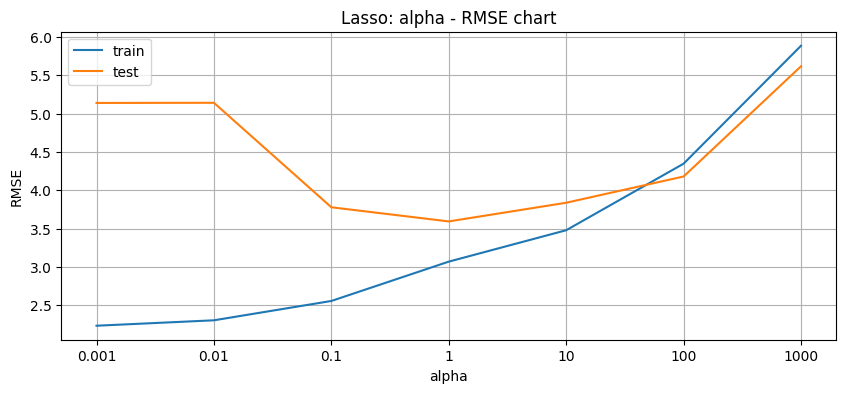

In [ ]:
plt.figure(figsize=(10, 4))

plt.plot(lasso_train_list, label="train")
plt.plot(lasso_test_list, label="test")

plt.title("Lasso: alpha - RMSE chart")
plt.xlabel("alpha")
plt.ylabel("RMSE")
plt.xticks(np.arange(len(alpha_list)), alpha_list)
plt.legend()
plt.grid()

# RMSE는 값이 작을수록 좋음 
# alpha값이 1~10 사이 정도가 가장 적절해보임을 알 수 있음 (train과 test의 차이가 가장 작은 구간)

In [100]:
# Ridge model 

alpha_list = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
ridge_train_list, ridge_test_list = [], []

for i in alpha_list:
    model_ri2 = Ridge(alpha=i, max_iter=10000)
    model_ri2.fit(X_train_poly, y_train)

    # train
    ridge_train_pred = model_ri2.predict(X_train_poly)
    ridge_train_RMSE = root_mean_squared_error(ridge_train_pred, y_train)
    ridge_train_list.append(round(ridge_train_RMSE, 4))

    # test
    ridge_test_pred = model_ri2.predict(X_test_poly)
    ridge_test_RMSE = root_mean_squared_error(ridge_test_pred, y_test)
    ridge_test_list.append(round(ridge_test_RMSE, 4))

/opt/anaconda3/envs/sesac-env/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:228: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 6.459663299930519e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


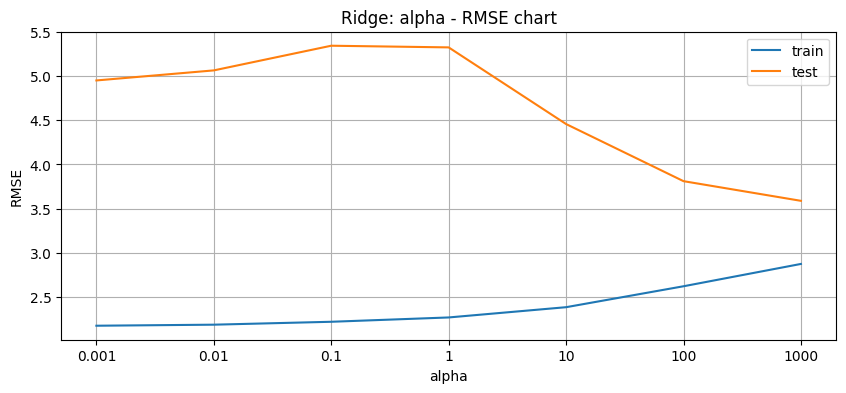

In [ ]:
plt.figure(figsize=(10, 4))

plt.plot(ridge_train_list, label="train")
plt.plot(ridge_test_list, label="test")

plt.title("Ridge: alpha - RMSE chart")
plt.xlabel("alpha")
plt.ylabel("RMSE")
plt.xticks(np.arange(len(alpha_list)), alpha_list)
plt.legend()
plt.grid()

# RMSE는 값이 작을수록 좋음 
# alpha값이 1000일 때 가장 성능이 좋고 과대적합이 해소됨을 알 수 있음 

### 11.2 결론 

- 현재 보스턴 집값 데이터에서는 alpha가 10일 때 Ridge모델에 비해 Lasso 모델의 train, test 오차 값의 차이가 적기 때문에 과대적합에 더 유리한 모델과 하이퍼파라미터라고 볼 수 있음